In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from src.preprocessing import get_preprocessor

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

X_train, y_train = train.drop(columns=["Churn"]), train["Churn"]
X_test, y_test = test.drop(columns=["Churn"]), test["Churn"]

print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [2]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, dummy_pred), 3))
print("Churners caught:", (dummy_pred[y_test == 1] == 1).sum(), "of", (y_test == 1).sum())

Accuracy: 0.735
Churners caught: 0 of 374


In [3]:
log_reg = Pipeline(steps=[
    ("preprocess", get_preprocessor(X_train)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

log_reg.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [4]:
y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

Accuracy: 0.804
ROC-AUC: 0.842


In [5]:
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.80      0.80      1409



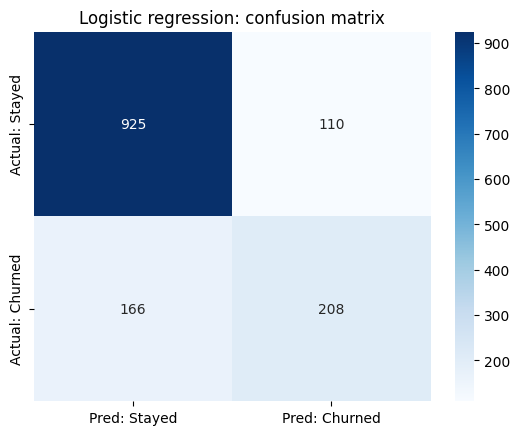

In [6]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: Stayed", "Pred: Churned"],
            yticklabels=["Actual: Stayed", "Actual: Churned"])
plt.title("Logistic regression: confusion matrix")
plt.show()

In [7]:
feature_names = log_reg.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=feature_names).sort_values()

print("Pushes toward STAYING:")
print(coefs.head(8).round(2))
print("\nPushes toward CHURNING:")
print(coefs.tail(8).round(2))

Pushes toward STAYING:
cat__InternetService_No                        -1.26
num__tenure                                    -1.25
cat__Contract_Two year                         -0.91
cat__PhoneService_Yes                          -0.40
cat__OnlineSecurity_Yes                        -0.38
cat__TechSupport_Yes                           -0.33
cat__PaymentMethod_Credit card (automatic)     -0.32
cat__PaymentMethod_Bank transfer (automatic)   -0.29
dtype: float64

Pushes toward CHURNING:
cat__SeniorCitizen_1                0.15
cat__StreamingMovies_Yes            0.31
cat__StreamingTV_Yes                0.31
cat__MultipleLines_Yes              0.33
cat__PaperlessBilling_Yes           0.37
cat__Contract_Month-to-month        0.44
num__TotalCharges                   0.52
cat__InternetService_Fiber optic    0.78
dtype: float64


## Baseline summary
- A model that always predicts "no churn" gets about 73.5% accuracy but catches no churners.
- Logistic regression reaches about 80% accuracy and ROC-AUC of about 0.84.
- Recall for churners is only about 55%, so it misses many customers who leave.
- Next: try tree-based models and handle the class imbalance.
